In [63]:
import os
import numpy as np
import pandas as pd
import seaborn as sb
import nibabel as nb
import nitools as nt
import pingouin as pg
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import imaging_pipelines.vis as ip_vis
import EFC_learningfMRI.globals as gl
import EFC_learningfMRI.vis as vis
import EFC_learningfMRI.util as util

In [64]:
glm = 3
H = 'L'
atlas = 'ROI'
rois = gl.rois[atlas]

hue_order = ['trained', 'untrained']
palette   = ['red', 'blue']

dist = pd.read_csv(os.path.join(gl.baseDir, gl.geomDir, f'dissimilarity.within_session.ROI.glm{glm}.tsv'), sep='\t')
dist = dist[(dist.Hem=='L') & (dist.chord.isin(hue_order))]
dist_sess = dist.groupby(['sn', 'Hem', 'roi', 'session']).mean(numeric_only=True).reset_index()
dist_chord_sess = dist.groupby(['sn', 'Hem', 'roi', 'session', 'chord']).mean(numeric_only=True).reset_index()

           T  dof     p_val           CI95   roi  session
0  -0.536513   15  0.599471  [-0.02, 0.01]   SMA        3
3  -0.339298   15  0.739089  [-0.02, 0.01]   PMd        3
6  -0.512439   15  0.615806  [-0.03, 0.02]   PMv        3
9  -0.316506   15  0.755981  [-0.05, 0.04]    M1        3
12 -0.622612   15  0.542890  [-0.04, 0.02]    S1        3
15 -1.163322   15  0.262871  [-0.05, 0.01]  SPLa        3
18 -0.865556   15  0.400366  [-0.05, 0.02]  SPLp        3
1   0.171311   15  0.866269  [-0.02, 0.02]   SMA        9
4  -1.050129   15  0.310284  [-0.03, 0.01]   PMd        9
7  -0.196098   15  0.847165  [-0.03, 0.03]   PMv        9
10  0.926154   15  0.369028  [-0.02, 0.05]    M1        9
13  0.860983   15  0.402801  [-0.03, 0.06]    S1        9
16 -0.035643   15  0.972037  [-0.03, 0.03]  SPLa        9
19 -0.145276   15  0.886427  [-0.03, 0.03]  SPLp        9
2  -0.843297   15  0.412309  [-0.01, 0.01]   SMA       23
5  -0.383190   15  0.706955  [-0.02, 0.01]   PMd       23
8  -2.028013  

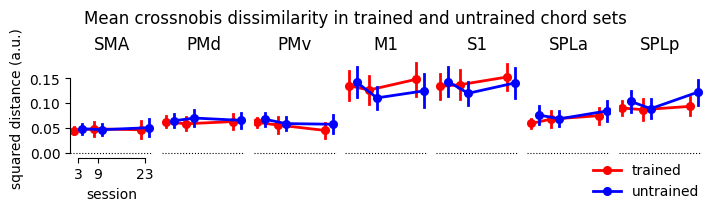

In [65]:
fig, axs = plt.subplots(1, len(rois), sharey=True, sharex=True, figsize=(7, 2), constrained_layout=True)

#vis.plot_im_sess(fig, axs, diss_within, rois, y='dist', x='session', hue='chord', hue_order=hue_order, palette=palette, kind='box', legend=False, alpha=.3)
vis.plot_im_sess(fig, axs, dist_chord_sess, rois, y='crossnobis', x='session', hue='chord', hue_order=hue_order, palette=palette, kind='point', estimator='mean', dodge=.4, add_zero=True)
sb.despine(ax=axs[0], trim=True)
axs[0].set_ylabel('squared distance (a.u.)')
axs[-1].legend([], frameon=False, loc='upper right')
fig.legend(frameon=False, loc='lower right')
axs[0].set_xlabel('session')

fig.suptitle('Mean crossnobis dissimilarity in trained and untrained chord sets')

ttest = util.ttest_im_sess(dist_chord_sess, rois, y='crossnobis', x='session', hue='chord', hue_order=hue_order)
ttest['roi'] = pd.Categorical(ttest.roi, categories=rois, ordered=True)  # ROIs in gl.rois[atlas] order
ttest.sort_values(by=['session', 'roi'], inplace=True)

print(ttest[['T', 'dof', 'p_val', 'CI95', 'roi', 'session']])

fig.savefig(os.path.join(gl.figDir, 'crossnobis_mean.pdf'))

plt.show()

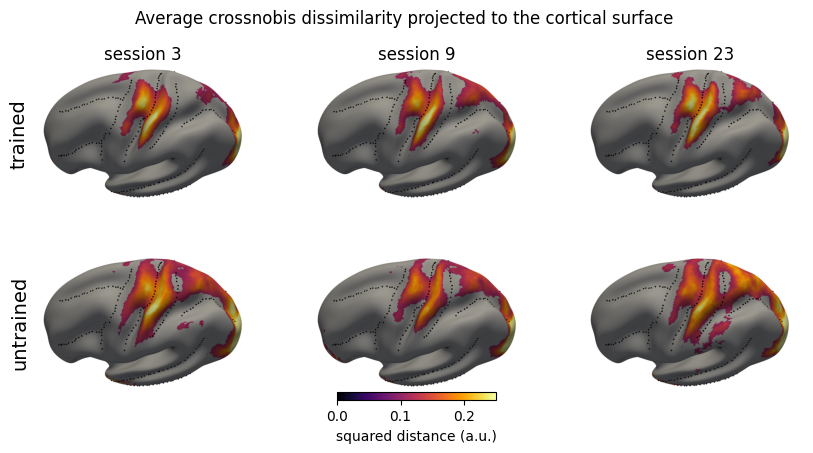

In [66]:
thresh = .1
vmin, vmax = 0, .25
H = 'L'

fig, axs = plt.subplots(2, 3, sharex=True, sharey=True, figsize=(10, 4.5), )

cmap = 'inferno'

for s, session in enumerate(gl.sessions):
    ax       = axs[:, s]
    gifti    = nb.load(os.path.join(gl.baseDir, gl.surfDir, f'searchlight_crossnobis.{session}.glm{glm}.{H}.func.gii'))
    cols     = nt.get_gifti_column_names(gifti)
    tr_col   = cols.index('crossnobis-trained')
    untr_col = cols.index('crossnobis-untrained')
    ip_vis.plot_surf(fig, ax[0], gifti, H, cmap=cmap, col=tr_col, thresh=thresh, vmin=vmin, vmax=vmax)
    ip_vis.plot_surf(fig, ax[1], gifti, H, cmap=cmap, col=untr_col, thresh=thresh, vmin=vmin, vmax=vmax)
    ax[0].set_title(f'session {session}')

sm  = plt.cm.ScalarMappable(norm=mcolors.Normalize(vmin=vmin, vmax=vmax), cmap=cmap)
cax = axs[1, 1].inset_axes([.15, -.10, .7, .06])          # x0, y0, w, h in axes fractions
fig.colorbar(sm, cax=cax, orientation='horizontal', label='squared distance (a.u.)')

axs[0, 0].text(0, .5, 'trained', transform=axs[0, 0].transAxes, rotation=90, ha='right', va='center', fontsize=14)
axs[1, 0].text(0, .5, 'untrained', transform=axs[1, 0].transAxes, rotation=90, ha='right', va='center', fontsize=14)

fig.suptitle('Average crossnobis dissimilarity projected to the cortical surface')

fig.savefig(os.path.join(gl.figDir, 'crossnobis_searchlight.pdf'), dpi=600)

plt.show()

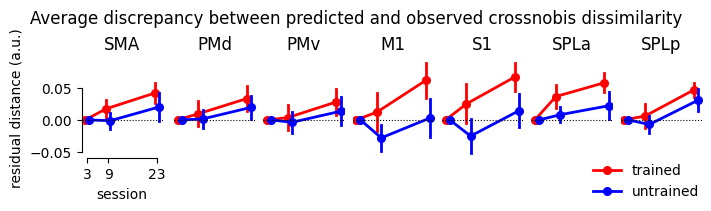

In [67]:
scaling = pd.read_csv(os.path.join(gl.baseDir, gl.geomDir, f'scaling.between_session.glm{glm}.{atlas}.tsv'), sep='\t')
scaling = scaling[scaling.Hem==H]

fig, axs = plt.subplots(1, len(rois), sharey=True, sharex=True, figsize=(7, 2), constrained_layout=True)

vis.plot_im_sess(fig, axs, scaling, rois=rois, roi_col='roi', y='residual', hue='chord', hue_order=['trained', 'untrained'], palette=['red', 'blue'], estimator='mean', add_zero=True)
sb.despine(ax=axs[0], trim=True)
axs[-1].legend([], frameon=False, loc='upper right')
fig.legend(frameon=False, loc='lower right',)
axs[0].set_xlabel('session')

axs[0].set_ylabel('residual distance (a.u.)')

fig.suptitle('Average discrepancy between predicted and observed crossnobis dissimilarity')

fig.savefig(os.path.join(gl.figDir, 'scaling.pdf'))

In [68]:
scaling_aov = scaling[(scaling.session != 3) & (scaling.chord.isin(hue_order))]

anova = []
for roi in rois:
    data       = scaling_aov[scaling_aov.roi == roi]
    aov        = pg.rm_anova(data=data, dv='residual', within=['session', 'chord'], subject='sn')
    aov['roi'] = roi
    anova.append(aov)
anova = pd.concat(anova, ignore_index=True)

print(anova[['roi', 'Source', 'F', 'ddof1', 'ddof2', 'p_unc']].round(3).to_string(index=False))

 roi          Source      F  ddof1  ddof2  p_unc
 SMA         session  3.184      1     15  0.095
 SMA           chord  2.139      1     15  0.164
 SMA session * chord  0.043      1     15  0.838
 PMd         session  0.933      1     14  0.351
 PMd           chord  0.756      1     14  0.399
 PMd session * chord  0.554      1     14  0.469
 PMv         session  2.253      1     15  0.154
 PMv           chord  0.523      1     15  0.481
 PMv session * chord  0.073      1     15  0.790
  M1         session  2.588      1     14  0.130
  M1           chord  5.427      1     14  0.035
  M1 session * chord  1.918      1     14  0.188
  S1         session  2.402      1     14  0.143
  S1           chord 12.754      1     14  0.003
  S1 session * chord  0.415      1     14  0.530
SPLa         session  0.992      1     15  0.335
SPLa           chord  4.534      1     15  0.050
SPLa session * chord  0.420      1     15  0.527
SPLp         session  4.936      1     15  0.042
SPLp           chord

In [69]:
# paired t-test of the residual, trained vs untrained, in sessions 9 and 23 separately (uncorrected p-values)
ttest_scaling = util.ttest_im_sess(scaling_aov, rois, y='residual', x='session', hue='chord', hue_order=hue_order, alternative='greater')
ttest_scaling['roi'] = pd.Categorical(ttest_scaling.roi, categories=rois, ordered=True)  # ROIs in gl.rois[atlas] order
ttest_scaling = ttest_scaling.sort_values(by=['session', 'roi'])

print(ttest_scaling[['roi', 'session', 'T', 'dof', 'p_val', 'CI95']].round(3).to_string(index=False))

 roi  session     T  dof  p_val         CI95
 SMA        9 1.132   15  0.138 [-0.01, inf]
 PMd        9 0.354   14  0.364 [-0.02, inf]
 PMv        9 0.311   15  0.380 [-0.03, inf]
  M1        9 1.635   14  0.062  [-0.0, inf]
  S1        9 2.978   14  0.005  [0.02, inf]
SPLa        9 1.625   15  0.063  [-0.0, inf]
SPLp        9 0.670   15  0.256 [-0.02, inf]
 SMA       23 1.413   15  0.089 [-0.01, inf]
 PMd       23 1.173   15  0.130 [-0.01, inf]
 PMv       23 0.879   15  0.197 [-0.01, inf]
  M1       23 2.031   15  0.030  [0.01, inf]
  S1       23 2.976   15  0.005  [0.02, inf]
SPLa       23 2.425   15  0.014  [0.01, inf]
SPLp       23 1.205   15  0.123 [-0.01, inf]


In [70]:
# angle between chord patterns (radians), from the cosine distance (1 - cos) adjusted for the group geometry;
# the angle is taken per chord pair, then averaged within each session and chord set
dist_ancova = pd.read_csv(os.path.join(gl.baseDir, gl.geomDir, f'dissimilarity_ancova_group.within_session.{atlas}.glm{glm}.tsv'), sep='\t')
dist_ancova = dist_ancova[(dist_ancova.Hem==H) & (dist_ancova.distance=='cosine')].copy()

# the adjustment pushes ~4% of pairs below 0 cosine distance (cosine > 1): clip them to an angle of 0
cos_sim = 1 - dist_ancova.adjusted
cos_sim = cos_sim.clip(upper=1)
dist_ancova['angle'] = np.arccos(cos_sim)

angle_chord_sess_ancova = dist_ancova.groupby(['sn', 'Hem', 'roi', 'session', 'chord']).mean(numeric_only=True).reset_index()

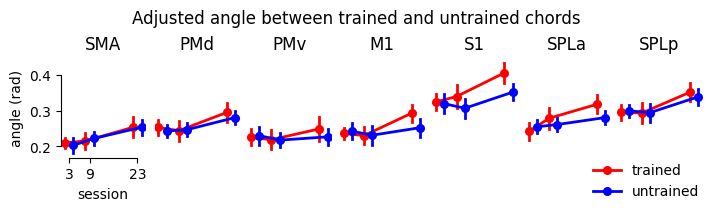

In [71]:
fig, axs = plt.subplots(1, len(rois), sharey=True, sharex=True, figsize=(7, 2), constrained_layout=True)

vis.plot_im_sess(fig, axs, angle_chord_sess_ancova, rois, y='angle', x='session', hue='chord', hue_order=hue_order,
                 palette=palette, kind='point', estimator='mean', dodge=.4, add_zero=False)

axs[-1].legend([], frameon=False, loc='upper right')
fig.legend(frameon=False, loc='lower right')
sb.despine(ax=axs[0], trim=True)
axs[0].set_ylabel('angle (rad)')
axs[0].set_xlabel('session')

fig.suptitle('Adjusted angle between trained and untrained chords')

fig.savefig(os.path.join(gl.figDir, 'adjusted_angular.pdf'))

plt.show()

In [72]:
# paired t-test of the adjusted angle, trained vs untrained, per ROI and session (uncorrected p-values)
ttest_cos = util.ttest_im_sess(angle_chord_sess_ancova, rois, y='angle', x='session', hue='chord', hue_order=hue_order, alternative='greater')
ttest_cos['roi'] = pd.Categorical(ttest_cos.roi, categories=rois, ordered=True)  # ROIs in gl.rois[atlas] order
ttest_cos = ttest_cos.sort_values(by=['session', 'roi'])

print(ttest_cos[['roi', 'session', 'T', 'dof', 'p_val', 'CI95']].round(3).to_string(index=False))

 roi  session      T  dof  p_val         CI95
 SMA        3  0.304   15  0.383 [-0.03, inf]
 PMd        3  0.589   15  0.282 [-0.02, inf]
 PMv        3 -0.222   15  0.586 [-0.04, inf]
  M1        3 -0.339   15  0.630 [-0.04, inf]
  S1        3  0.266   15  0.397 [-0.03, inf]
SPLa        3 -0.631   15  0.731 [-0.05, inf]
SPLp        3 -0.213   15  0.583 [-0.04, inf]
 SMA        9 -0.449   15  0.670 [-0.03, inf]
 PMd        9 -0.125   15  0.549 [-0.04, inf]
 PMv        9  0.056   15  0.478 [-0.04, inf]
  M1        9 -0.050   15  0.520 [-0.04, inf]
  S1        9  1.689   15  0.056  [-0.0, inf]
SPLa        9  1.037   15  0.158 [-0.01, inf]
SPLp        9 -0.060   15  0.523 [-0.03, inf]
 SMA       23  0.007   15  0.497 [-0.05, inf]
 PMd       23  0.867   15  0.200 [-0.01, inf]
 PMv       23  1.168   15  0.131 [-0.01, inf]
  M1       23  2.573   15  0.011  [0.01, inf]
  S1       23  2.521   15  0.012  [0.02, inf]
SPLa       23  2.263   15  0.019  [0.01, inf]
SPLp       23  0.711   15  0.244 [